In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import joblib

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load and Verify the Clustering Dataset

The clustering-ready dataset prepared during the Data Preparation stage is loaded for analysis. The dataset is checked for its dimensions, feature names and missing values before applying K-Means clustering.

In [2]:
DATA_PATH = "ATS_cluster_ready_v1.csv"

X_cluster = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Number of records:", X_cluster.shape[0])
print("Number of features:", X_cluster.shape[1])
print("\nFeature names:")
print(X_cluster.columns.tolist())

print("\nTotal missing values:", X_cluster.isnull().sum().sum())

X_cluster.head()

Dataset loaded successfully.
Number of records: 6741
Number of features: 10

Feature names:
['gender', 'SeniorCitizen', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'MonthlyCharges', 'InternetService_Fiber optic', 'Contract_One year', 'Contract_Two year']

Total missing values: 0


,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,MonthlyCharges,InternetService_Fiber optic,Contract_One year,Contract_Two year
0,0,0,0,-1.312875,0,0,-1.376228,0,0,0
1,1,0,0,0.331038,1,0,-1.376228,0,1,0
2,0,0,1,0.783114,1,0,-1.578399,0,0,0
3,0,0,0,-1.312875,1,0,0.342225,0,1,0
4,1,0,0,1.399582,1,0,-0.500154,1,0,0


## 3. Determine the Optimal Number of Clusters

The Elbow Method is used to help determine an appropriate number of clusters for K-Means. K-Means models are trained using different values of K from 1 to 10, and the Within-Cluster Sum of Squares (WCSS), represented by model inertia, is calculated for each value.

The point where the reduction in inertia begins to slow down forms an "elbow" in the graph and provides an indication of an appropriate number of customer clusters.

C:\Users\bishw\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\bishw\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Program Files\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Program Files\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Program Files\Python312\Lib\subprocess.py", line 1538, in _execute_ch

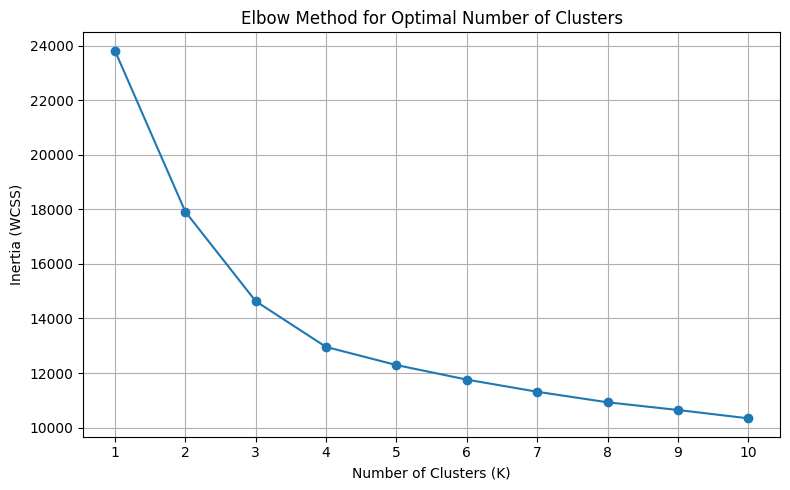

K = 1: Inertia = 23823.26
K = 2: Inertia = 17918.02
K = 3: Inertia = 14634.40
K = 4: Inertia = 12956.38
K = 5: Inertia = 12291.47
K = 6: Inertia = 11757.57
K = 7: Inertia = 11312.20
K = 8: Inertia = 10925.12
K = 9: Inertia = 10643.53
K = 10: Inertia = 10336.91


In [3]:
inertias = []
k_values = range(1, 11)

for k in k_values:
    kmeans_test = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )
    
    kmeans_test.fit(X_cluster)
    inertias.append(kmeans_test.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xticks(k_values)
plt.grid(True)
plt.tight_layout()

plt.savefig("elbow_method.png", dpi=300, bbox_inches="tight")
plt.show()

for k, inertia in zip(k_values, inertias):
    print(f"K = {k}: Inertia = {inertia:.2f}")

## 4. Silhouette Analysis

To support the selection of the optimal number of clusters, Silhouette Scores are calculated for K values from 2 to 10. The Silhouette Score measures how well each customer fits within its assigned cluster compared with other clusters. A higher score indicates better separation and cohesion between customer segments.

The Silhouette results are considered together with the Elbow Method when selecting the final number of clusters.

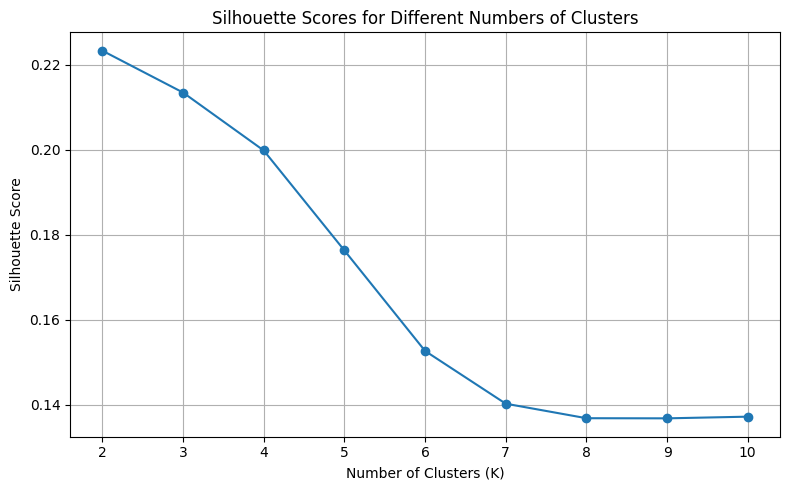

K = 2: Silhouette Score = 0.2233
K = 3: Silhouette Score = 0.2134
K = 4: Silhouette Score = 0.1998
K = 5: Silhouette Score = 0.1763
K = 6: Silhouette Score = 0.1527
K = 7: Silhouette Score = 0.1403
K = 8: Silhouette Score = 0.1368
K = 9: Silhouette Score = 0.1368
K = 10: Silhouette Score = 0.1372


In [4]:
silhouette_scores = []
silhouette_k_values = range(2, 11)

for k in silhouette_k_values:
    kmeans_test = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )
    
    labels = kmeans_test.fit_predict(X_cluster)
    score = silhouette_score(X_cluster, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(silhouette_k_values, silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Scores for Different Numbers of Clusters")
plt.xticks(silhouette_k_values)
plt.grid(True)
plt.tight_layout()

plt.savefig("silhouette_scores.png", dpi=300, bbox_inches="tight")
plt.show()

for k, score in zip(silhouette_k_values, silhouette_scores):
    print(f"K = {k}: Silhouette Score = {score:.4f}")

### 4.1 Selection of the Optimal Number of Clusters

The Elbow Method shows a noticeable reduction in the rate of improvement after approximately K = 4, indicating that four clusters provide a reasonable balance between reducing within-cluster variation and avoiding unnecessary additional clusters.

The Silhouette analysis produced the highest score at K = 2 (0.2233), while K = 4 achieved a score of 0.1998. Although K = 2 provides stronger overall cluster separation, K = 4 was selected for the final K-Means model because the Elbow Method indicates a meaningful bend around four clusters and four segments provide a more detailed basis for customer segmentation and business interpretation.

Therefore, the selected number of clusters for the final K-Means model is K = 4.

In [5]:
optimal_k = 4

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=RANDOM_STATE,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_cluster)

print("K-Means model trained successfully.")
print("Selected number of clusters:", optimal_k)

print("\nNumber of customers in each cluster:")
cluster_counts = pd.Series(cluster_labels).value_counts().sort_index()

for cluster, count in cluster_counts.items():
    print(f"Cluster {cluster}: {count} customers")

K-Means model trained successfully.
Selected number of clusters: 4

Number of customers in each cluster:
Cluster 0: 1586 customers
Cluster 1: 1882 customers
Cluster 2: 1123 customers
Cluster 3: 2150 customers


## 6. Customer Cluster Profiling

To interpret the four customer segments, the cluster assignments are combined with the cleaned dataset containing the original customer characteristics. This allows each cluster to be compared using variables such as tenure, monthly charges, contract type, internet service and churn behaviour.

The Churn variable was not used to create the clusters. It is included only after clustering to help interpret the business characteristics and churn behaviour of each customer segment.

In [6]:
df_clean = pd.read_csv("ATS_clean_v1.csv")

print("Clean dataset records:", len(df_clean))
print("Cluster assignments:", len(cluster_labels))

assert len(df_clean) == len(cluster_labels), \
    "The clean dataset and cluster assignments do not have the same number of records."

df_results = df_clean.copy()
df_results["Cluster"] = cluster_labels

print("\nCluster assignments added successfully.")
print("\nColumns available for profiling:")
print(df_results.columns.tolist())

df_results.head()

Clean dataset records: 6741
Cluster assignments: 6741

Cluster assignments added successfully.

Columns available for profiling:
['gender', 'SeniorCitizen', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'MonthlyCharges', 'Churn', 'InternetService_Fiber optic', 'Contract_One year', 'Contract_Two year', 'Cluster']


,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,MonthlyCharges,Churn,InternetService_Fiber optic,Contract_One year,Contract_Two year,Cluster
0,0,0,0,1,0,0,25,1,0,0,0,0
1,1,0,0,41,1,0,25,0,0,1,0,2
2,0,0,1,52,1,0,19,0,0,0,0,2
3,0,0,0,1,1,0,76,1,0,1,0,3
4,1,0,0,67,1,0,51,0,1,0,0,2


### 6.1 Cluster Characteristics

The characteristics of each customer cluster are summarised using the original customer values. Average tenure and monthly charges are calculated for each segment, while binary variables are presented as percentages. Churn rate is also examined after clustering to support business interpretation; it was not used as an input to the K-Means model.

In [7]:
cluster_profile = df_results.groupby("Cluster").agg(
    Customers=("Cluster", "size"),
    Avg_Tenure=("tenure", "mean"),
    Avg_MonthlyCharges=("MonthlyCharges", "mean"),
    Churn_Rate=("Churn", "mean"),
    SeniorCitizen_Rate=("SeniorCitizen", "mean"),
    Dependents_Rate=("Dependents", "mean"),
    PhoneService_Rate=("PhoneService", "mean"),
    MultipleLines_Rate=("MultipleLines", "mean"),
    FiberOptic_Rate=("InternetService_Fiber optic", "mean"),
    OneYearContract_Rate=("Contract_One year", "mean"),
    TwoYearContract_Rate=("Contract_Two year", "mean")
)

percentage_columns = [
    "Churn_Rate",
    "SeniorCitizen_Rate",
    "Dependents_Rate",
    "PhoneService_Rate",
    "MultipleLines_Rate",
    "FiberOptic_Rate",
    "OneYearContract_Rate",
    "TwoYearContract_Rate"
]

cluster_profile[percentage_columns] = (
    cluster_profile[percentage_columns] * 100
)

cluster_profile = cluster_profile.round(2)

cluster_profile

,Customers,Avg_Tenure,Avg_MonthlyCharges,Churn_Rate,SeniorCitizen_Rate,Dependents_Rate,PhoneService_Rate,MultipleLines_Rate,FiberOptic_Rate,OneYearContract_Rate,TwoYearContract_Rate
Cluster,,,,,,,,,,,
0,1586,11.24,33.80,24.91,7.19,33.10,77.74,42.62,44.14,24.09,24.46
1,1882,58.73,93.17,15.62,21.57,33.58,99.57,43.46,45.32,20.83,24.12
2,1123,54.35,34.90,4.81,7.75,44.88,72.66,40.43,44.35,22.08,23.86
3,2150,15.21,81.72,48.74,24.33,18.14,99.77,41.77,42.51,19.40,25.07


### 6.2 Cluster Interpretation and Labels

Based on the cluster profiles, descriptive labels are assigned to make the customer segments easier to interpret. The labels are based primarily on differences in customer tenure, monthly charges and observed churn behaviour.

- **Cluster 0 – Newer, Lower-Spend Customers:** Customers have relatively short average tenure (11.24 months), low average monthly charges ($33.80), and an observed churn rate of 24.91%.
- **Cluster 1 – Long-Term, High-Value Customers:** Customers have long average tenure (58.73 months) and the highest average monthly charges ($93.17). Their observed churn rate is comparatively lower at 15.62%.
- **Cluster 2 – Long-Term, Low-Risk Customers:** Customers have long average tenure (54.35 months), relatively low average monthly charges ($34.90), and the lowest observed churn rate at 4.81%.
- **Cluster 3 – Newer, High-Risk Customers:** Customers have relatively short average tenure (15.21 months), high average monthly charges ($81.72), and the highest observed churn rate at 48.74%.

These labels are descriptive interpretations of the customer segments. Churn was not used to train the K-Means model; the observed churn rates were analysed after clustering to support business interpretation.

In [9]:
cluster_names = {
    0: "Newer, Lower-Spend Customers",
    1: "Long-Term, High-Value Customers",
    2: "Long-Term, Low-Risk Customers",
    3: "Newer, High-Risk Customers"
}

df_results["Cluster_Label"] = df_results["Cluster"].map(cluster_names)

print("Cluster labels added successfully.")

print("\nCustomers in each segment:")
print(df_results["Cluster_Label"].value_counts())

df_results.head()

Cluster labels added successfully.

Customers in each segment:
Cluster_Label
Newer, High-Risk Customers         2150
Long-Term, High-Value Customers    1882
Newer, Lower-Spend Customers       1586
Long-Term, Low-Risk Customers      1123
Name: count, dtype: int64


,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,MonthlyCharges,Churn,InternetService_Fiber optic,Contract_One year,Contract_Two year,Cluster,Cluster_Label
0,0,0,0,1,0,0,25,1,0,0,0,0,"Newer, Lower-Spend Customers"
1,1,0,0,41,1,0,25,0,0,1,0,2,"Long-Term, Low-Risk Customers"
2,0,0,1,52,1,0,19,0,0,0,0,2,"Long-Term, Low-Risk Customers"
3,0,0,0,1,1,0,76,1,0,1,0,3,"Newer, High-Risk Customers"
4,1,0,0,67,1,0,51,0,1,0,0,2,"Long-Term, Low-Risk Customers"


## 7. Cluster Visualisation

The customer clusters are visualised using tenure and monthly charges, two important continuous customer characteristics. This visualisation helps demonstrate how the identified customer segments differ in terms of customer relationship length and monthly spending.

The chart represents a two-dimensional view of the clusters and does not display all ten features used by the K-Means model.

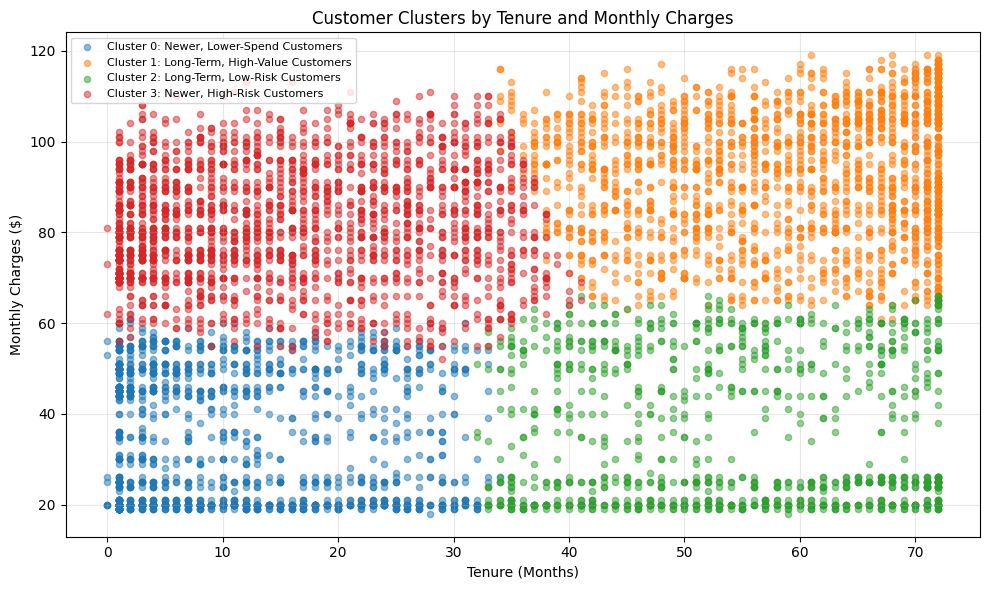

In [10]:
plt.figure(figsize=(10, 6))

for cluster in sorted(df_results["Cluster"].unique()):
    cluster_data = df_results[df_results["Cluster"] == cluster]
    
    plt.scatter(
        cluster_data["tenure"],
        cluster_data["MonthlyCharges"],
        label=f"Cluster {cluster}: {cluster_names[cluster]}",
        alpha=0.5,
        s=20
    )

plt.xlabel("Tenure (Months)")
plt.ylabel("Monthly Charges ($)")
plt.title("Customer Clusters by Tenure and Monthly Charges")
plt.legend(fontsize=8)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "cluster_visualisation_tenure_charges.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 7.1 Visualisation Interpretation

The tenure and monthly charges visualisation shows clear differences between the four customer segments. Cluster 0 mainly represents customers with shorter tenure and lower monthly charges, while Cluster 3 contains many customers with shorter tenure and higher monthly charges. In contrast, Clusters 1 and 2 generally contain customers with longer tenure, with Cluster 1 showing higher monthly charges and Cluster 2 showing lower monthly charges.

When compared with the post-clustering churn analysis, Cluster 3 has the highest observed churn rate (48.74%), while Cluster 2 has the lowest observed churn rate (4.81%). This suggests that the customer segments identified through K-Means may support different retention and engagement strategies.

This two-dimensional visualisation is provided for interpretation purposes; the K-Means model itself was trained using all ten clustering features.

## 8. Save the Trained K-Means Model and Clustering Results

The final trained K-Means model and customer cluster assignments are saved for use in the project repository, further analysis and reporting.

In [11]:
joblib.dump(kmeans, "trained_kmeans_model.pkl")

df_results.to_csv(
    "clustering_results.csv",
    index=False
)

cluster_profile.to_csv(
    "cluster_profile_summary.csv"
)

print("Files saved successfully:")
print("- trained_kmeans_model.pkl")
print("- clustering_results.csv")
print("- cluster_profile_summary.csv")

Files saved successfully:
- trained_kmeans_model.pkl
- clustering_results.csv
- cluster_profile_summary.csv


## 9. Business Insights and Actionable Recommendations

The K-Means analysis identified four distinct customer segments with different tenure, spending and observed churn characteristics. These segments can support more targeted customer retention and engagement strategies.

### Cluster 0 – Newer, Lower-Spend Customers
This segment contains 1,586 customers with an average tenure of 11.24 months and average monthly charges of $33.80. The observed churn rate is 24.91%.

**Recommended action:** Focus on early customer engagement, onboarding support and targeted offers designed to encourage longer-term relationships.

### Cluster 1 – Long-Term, High-Value Customers
This segment contains 1,882 customers with an average tenure of 58.73 months and the highest average monthly charges at $93.17. The observed churn rate is 15.62%.

**Recommended action:** Prioritise loyalty and retention initiatives for these established, higher-spending customers, such as personalised service, loyalty benefits and relevant value-added offers.

### Cluster 2 – Long-Term, Low-Risk Customers
This segment contains 1,123 customers with an average tenure of 54.35 months, average monthly charges of $34.90 and the lowest observed churn rate at 4.81%.

**Recommended action:** Maintain customer satisfaction and explore appropriate cross-selling or service upgrade opportunities while preserving the value that may contribute to their long-term retention.

### Cluster 3 – Newer, High-Risk Customers
This is the largest segment with 2,150 customers. Customers have an average tenure of 15.21 months, relatively high average monthly charges of $81.72 and the highest observed churn rate at 48.74%.

**Recommended action:** Prioritise this segment for retention initiatives. Potential actions include early customer check-ins, service experience reviews, targeted retention offers and investigating whether customers perceive sufficient value relative to their monthly charges.

Overall, the clustering results suggest that customer retention strategies should be differentiated across customer segments rather than applying the same approach to all customers. The observed churn rates were analysed after clustering and were not used as inputs to the K-Means model.

## 10. Conclusion and Limitations

The clustering analysis successfully segmented 6,741 customers into four customer groups using K-Means clustering. The Elbow Method indicated a meaningful bend around K = 4, while Silhouette analysis was used as supporting evidence. The resulting clusters showed meaningful differences in customer tenure, monthly charges and post-clustering churn behaviour.

The analysis identified Cluster 3 as a particularly important segment for further retention analysis because it combines relatively short tenure, higher monthly charges and the highest observed churn rate. Cluster 2 showed the lowest observed churn rate and relatively long customer tenure.

Several limitations should be considered. K-Means uses Euclidean distance and works best when clusters have relatively compact structures. The dataset contains a mixture of scaled continuous features and encoded binary features, so the resulting distances are an approximation of customer similarity. In addition, the two-dimensional tenure and monthly charges visualisation does not represent all ten features used by the clustering model. Finally, the cluster labels and business recommendations are descriptive interpretations of the observed segments and should not be treated as evidence of causal relationships.